### 4G/5G Cellular Network Bandwidth Prediction and Energy Optimization Using Machine Learning

In [4]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.impute import KNNImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier,AdaBoostClassifier



from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,roc_auc_score
from sklearn.model_selection import train_test_split,GridSearchCV,RandomizedSearchCV

import warnings 
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

import datetime as datetime

In [5]:
df=pd.read_csv('Performance_5G_Weekday.txt')
df

,Base Station ID,Cell ID,Timestamp,PRB Usage Ratio (%),Traffic Volume (KByte),Number of Users,BBU Energy (W),RRU Energy (W),Channel Shutdown Time (Millisecond),Channel Shutdown Time (Millisecond).1,Deep Sleep Time (Millisecond)
0,13905,13905-2,00:00,6.38,901779.61,8.43,127.100000,131.700000,0.0,0.0,0.0
1,13905,13905-2,00:30,5.75,421101.82,7.16,126.300000,126.900000,0.0,0.0,0.0
2,13905,13905-2,01:00,6.79,557501.69,8.08,126.300000,130.700000,0.0,0.0,0.0
3,13905,13905-2,01:30,5.68,235001.93,8.29,126.400000,130.200000,0.0,0.0,0.0
4,13905,13905-2,02:00,5.93,300708.05,8.86,126.300000,129.400000,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
1001275,14242,14242-2,21:30,24.06,4186463.81,27.06,181.395504,398.657195,0.0,0.0,0.0
1001276,14242,14242-2,22:00,24.53,3539629.95,25.65,181.395504,399.192490,0.0,0.0,0.0
1001277,14242,14242-2,22:30,25.97,3806065.30,30.74,181.395504,400.856115,0.0,0.0,0.0
1001278,14242,14242-2,23:00,26.55,4296543.10,32.52,181.395504,401.525225,0.0,0.0,0.0


In [6]:
df.isna().sum()

Base Station ID                          0
Cell ID                                  0
Timestamp                                0
PRB Usage Ratio (%)                      0
Traffic Volume (KByte)                   0
Number of Users                          0
BBU Energy (W)                           0
RRU Energy (W)                           0
Channel Shutdown Time (Millisecond)      0
Channel Shutdown Time (Millisecond).1    0
Deep Sleep Time (Millisecond)            0
dtype: int64

## IQR Check Fun

In [4]:
def check_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print(f"\nColumn: {column}")
    print(f"Q1: {Q1}")
    print(f"Q3: {Q3}")
    print(f"IQR: {IQR}")
    print(f"Lower Limit: {lower_limit}")
    print(f"Upper Limit: {upper_limit}")
    print(f"Number of Outliers: {len(outliers)}")

    return outliers

## PLOTS AND ALL RELVENT CHECKING:

In [5]:
def numerical_eda(df, column):

    data = df[column].dropna()

    print("=" * 50)
    print(f"Numerical EDA: {column}")
    print("=" * 50)

    # Basic information
    print(f"Data Type       : {df[column].dtype}")
    print(f"Null Count      : {df[column].isnull().sum()}")
    print(f"Null Percentage : {df[column].isnull().mean() * 100:.2f}%")
    print(f"Unique Values   : {df[column].nunique()}")

    # Statistics
    print("\n--- Statistics ---")
    print(f"Mean            : {data.mean():.2f}")
    print(f"Median          : {data.median():.2f}")
    print(f"Std Dev         : {data.std():.2f}")
    print(f"Minimum         : {data.min():.2f}")
    print(f"Maximum         : {data.max():.2f}")

    # Percentiles
    print("\n--- Percentiles ---")
    print(f"25%             : {data.quantile(0.25):.2f}")
    print(f"50%             : {data.quantile(0.50):.2f}")
    print(f"75%             : {data.quantile(0.75):.2f}")

    # Skewness
    print("\n--- Distribution ---")
    print(f"Skewness        : {data.skew():.3f}")

    # Histogram
    plt.figure(figsize=(8, 4))
    sns.histplot(data, kde=True)
    plt.title(f"Distribution - {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.show()

    # KDE
    plt.figure(figsize=(8, 4))
    sns.kdeplot(data, fill=True)
    plt.title(f"KDE Plot - {column}")
    plt.xlabel(column)
    plt.ylabel("Density")
    plt.show()

    # Box plot
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=data)
    plt.title(f"Box Plot - {column}")
    plt.xlabel(column)
    plt.show()

### Timestamp

In [6]:
df['Timestamp']

0          00:00
1          00:30
2          01:00
3          01:30
4          02:00
           ...  
1001275    21:30
1001276    22:00
1001277    22:30
1001278    23:00
1001279    23:30
Name: Timestamp, Length: 1001280, dtype: str

In [10]:
cols=df.columns

In [11]:
cols

Index(['Base Station ID', 'Cell ID', 'Timestamp', 'PRB Usage Ratio (%)',
       'Traffic Volume (KByte)', 'Number of Users', 'BBU Energy (W)',
       'RRU Energy (W)', 'Channel Shutdown Time (Millisecond)',
       'Channel Shutdown Time (Millisecond).1',
       'Deep Sleep Time (Millisecond)'],
      dtype='str')

### PRB Usage Ratio (%)

In [12]:
df['PRB Usage Ratio (%)']

0           6.38
1           5.75
2           6.79
3           5.68
4           5.93
           ...  
1001275    24.06
1001276    24.53
1001277    25.97
1001278    26.55
1001279    26.55
Name: PRB Usage Ratio (%), Length: 1001280, dtype: float64

Numerical EDA: PRB Usage Ratio (%)
Data Type       : float64
Null Count      : 0
Null Percentage : 0.00%
Unique Values   : 6555

--- Statistics ---
Mean            : 6.32
Median          : 5.66
Std Dev         : 6.09
Minimum         : 0.00
Maximum         : 99.62

--- Percentiles ---
25%             : 2.60
50%             : 5.66
75%             : 8.06

--- Distribution ---
Skewness        : 4.088


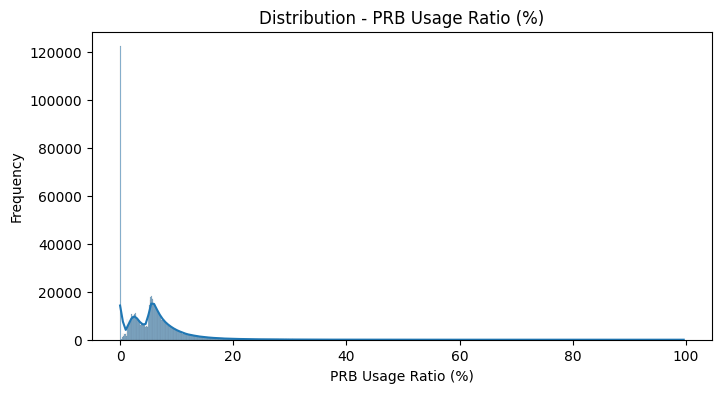

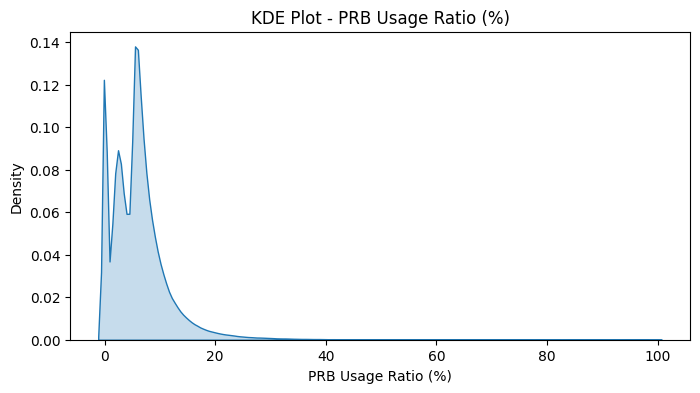

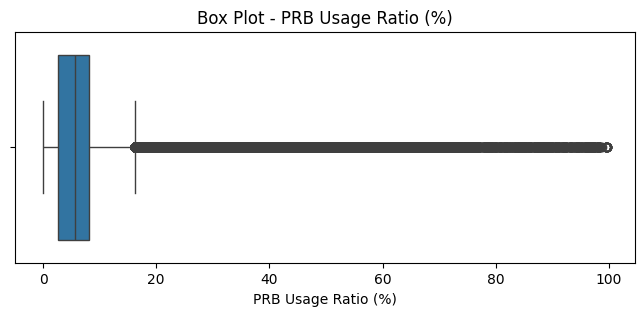

In [13]:
numerical_eda(df,'PRB Usage Ratio (%)')

In [14]:
check_outliers(df,'PRB Usage Ratio (%)')


Column: PRB Usage Ratio (%)
Q1: 2.6
Q3: 8.06
IQR: 5.460000000000001
Lower Limit: -5.590000000000002
Upper Limit: 16.25
Number of Outliers: 44701


,Base Station ID,Cell ID,Timestamp,PRB Usage Ratio (%),Traffic Volume (KByte),Number of Users,BBU Energy (W),RRU Energy (W),Channel Shutdown Time (Millisecond),Channel Shutdown Time (Millisecond).1,Deep Sleep Time (Millisecond)
304,13410,13410-2,08:00,28.03,19750334.09,10.21,131.400000,291.114047,0.0,0.0,0.0
305,13410,13410-2,08:30,44.68,35215154.34,10.97,131.600000,303.737766,0.0,0.0,0.0
306,13410,13410-2,09:00,30.04,22614257.17,13.69,131.800000,244.401387,0.0,0.0,0.0
309,13410,13410-2,10:30,71.62,52910683.40,17.28,132.600000,318.101005,0.0,0.0,0.0
310,13410,13410-2,11:00,60.07,44284138.02,13.81,132.700000,309.556090,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
1001275,14242,14242-2,21:30,24.06,4186463.81,27.06,181.395504,398.657195,0.0,0.0,0.0
1001276,14242,14242-2,22:00,24.53,3539629.95,25.65,181.395504,399.192490,0.0,0.0,0.0
1001277,14242,14242-2,22:30,25.97,3806065.30,30.74,181.395504,400.856115,0.0,0.0,0.0
1001278,14242,14242-2,23:00,26.55,4296543.10,32.52,181.395504,401.525225,0.0,0.0,0.0


In [16]:
cols

Index(['Base Station ID', 'Cell ID', 'Timestamp', 'PRB Usage Ratio (%)',
       'Traffic Volume (KByte)', 'Number of Users', 'BBU Energy (W)',
       'RRU Energy (W)', 'Channel Shutdown Time (Millisecond)',
       'Channel Shutdown Time (Millisecond).1',
       'Deep Sleep Time (Millisecond)'],
      dtype='str')

### Traffic Volume (KByte)

In [17]:
df['Traffic Volume (KByte)']

0           901779.61
1           421101.82
2           557501.69
3           235001.93
4           300708.05
              ...    
1001275    4186463.81
1001276    3539629.95
1001277    3806065.30
1001278    4296543.10
1001279    4693322.00
Name: Traffic Volume (KByte), Length: 1001280, dtype: float64

Numerical EDA: Traffic Volume (KByte)
Data Type       : float64
Null Count      : 0
Null Percentage : 0.00%
Unique Values   : 865532

--- Statistics ---
Mean            : 1495379.99
Median          : 587141.27
Std Dev         : 3382968.95
Minimum         : 0.00
Maximum         : 200809933.80

--- Percentiles ---
25%             : 91764.14
50%             : 587141.27
75%             : 1782335.71

--- Distribution ---
Skewness        : 14.862


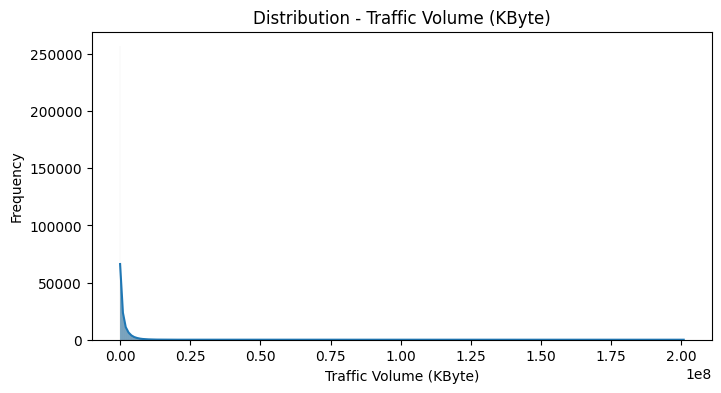

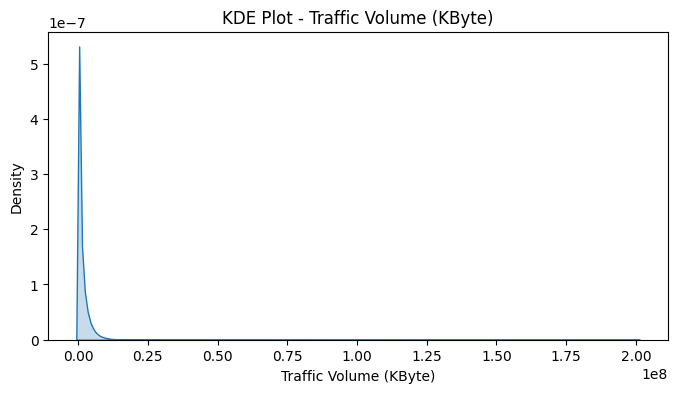

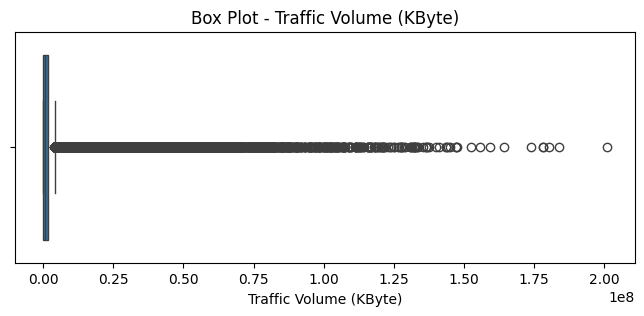

In [18]:
numerical_eda(df,'Traffic Volume (KByte)')

In [19]:
check_outliers(df,'Traffic Volume (KByte)')


Column: Traffic Volume (KByte)
Q1: 91764.1425
Q3: 1782335.7125
IQR: 1690571.5699999998
Lower Limit: -2444093.2124999994
Upper Limit: 4318193.067499999
Number of Outliers: 80993


,Base Station ID,Cell ID,Timestamp,PRB Usage Ratio (%),Traffic Volume (KByte),Number of Users,BBU Energy (W),RRU Energy (W),Channel Shutdown Time (Millisecond),Channel Shutdown Time (Millisecond).1,Deep Sleep Time (Millisecond)
304,13410,13410-2,08:00,28.03,19750334.09,10.21,131.400000,291.114047,0.0,0.0,0.0
305,13410,13410-2,08:30,44.68,35215154.34,10.97,131.600000,303.737766,0.0,0.0,0.0
306,13410,13410-2,09:00,30.04,22614257.17,13.69,131.800000,244.401387,0.0,0.0,0.0
309,13410,13410-2,10:30,71.62,52910683.40,17.28,132.600000,318.101005,0.0,0.0,0.0
310,13410,13410-2,11:00,60.07,44284138.02,13.81,132.700000,309.556090,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
1001237,14242,14242-2,02:30,54.49,8201514.39,27.09,181.395504,433.828483,0.0,0.0,0.0
1001257,14242,14242-2,12:30,32.76,4935303.69,17.74,181.395504,408.714351,0.0,0.0,0.0
1001270,14242,14242-2,19:00,23.40,4507482.23,24.35,181.395504,397.884638,0.0,0.0,0.0
1001271,14242,14242-2,19:30,22.51,4594608.54,24.78,181.395504,396.861391,0.0,0.0,0.0


In [22]:
df[df['Traffic Volume (KByte)']==0]

,Base Station ID,Cell ID,Timestamp,PRB Usage Ratio (%),Traffic Volume (KByte),Number of Users,BBU Energy (W),RRU Energy (W),Channel Shutdown Time (Millisecond),Channel Shutdown Time (Millisecond).1,Deep Sleep Time (Millisecond)
7,13905,13905-2,03:30,0.00,0.0,0.0,126.000000,55.000000,0.0,0.0,900000.0
8,13905,13905-2,04:00,0.00,0.0,0.0,126.000000,55.000000,0.0,0.0,900000.0
9,13905,13905-2,04:30,0.00,0.0,0.0,126.000000,54.800000,0.0,0.0,900000.0
55,13905,13905-1,03:30,0.00,0.0,0.0,126.000000,72.379919,0.0,0.0,900000.0
56,13905,13905-1,04:00,0.00,0.0,0.0,126.000000,71.452111,0.0,0.0,900000.0
...,...,...,...,...,...,...,...,...,...,...,...
1001049,14239,14239-1,04:30,5.11,0.0,0.0,181.395504,153.286246,0.0,0.0,0.0
1001097,14239,14239-2,04:30,5.49,0.0,0.0,181.395504,153.997406,0.0,0.0,0.0
1001145,14242,14242-0,04:30,12.30,0.0,0.0,181.395504,385.061949,0.0,0.0,0.0
1001193,14242,14242-1,04:30,10.92,0.0,0.0,181.395504,383.460004,0.0,0.0,0.0


In [23]:
cols

Index(['Base Station ID', 'Cell ID', 'Timestamp', 'PRB Usage Ratio (%)',
       'Traffic Volume (KByte)', 'Number of Users', 'BBU Energy (W)',
       'RRU Energy (W)', 'Channel Shutdown Time (Millisecond)',
       'Channel Shutdown Time (Millisecond).1',
       'Deep Sleep Time (Millisecond)'],
      dtype='str')

### Number of Users

In [24]:
df['Number of Users'] 

0           8.43
1           7.16
2           8.08
3           8.29
4           8.86
           ...  
1001275    27.06
1001276    25.65
1001277    30.74
1001278    32.52
1001279    32.27
Name: Number of Users, Length: 1001280, dtype: float64

Numerical EDA: Number of Users
Data Type       : float64
Null Count      : 0
Null Percentage : 0.00%
Unique Values   : 13625

--- Statistics ---
Mean            : 13.18
Median          : 6.65
Std Dev         : 18.41
Minimum         : 0.00
Maximum         : 475.73

--- Percentiles ---
25%             : 1.60
50%             : 6.65
75%             : 17.48

--- Distribution ---
Skewness        : 3.368


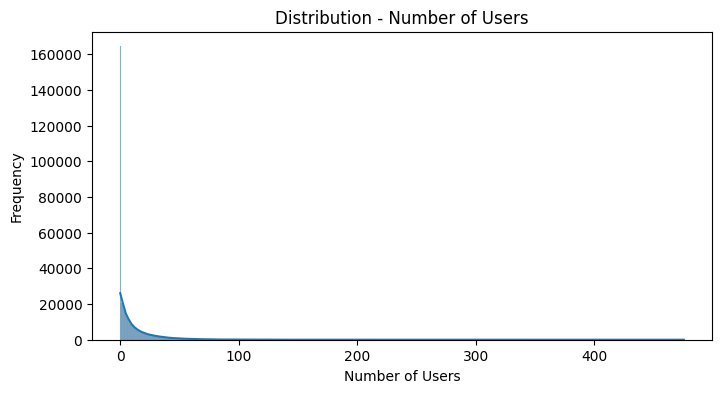

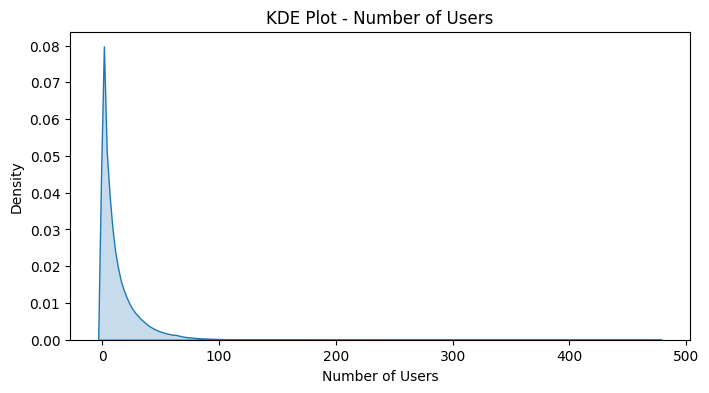

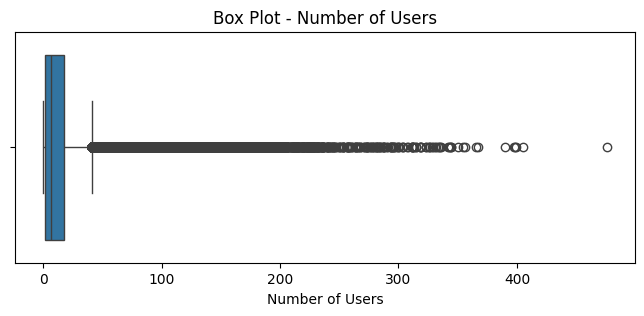

In [25]:
numerical_eda(df,'Number of Users')

In [26]:
check_outliers(df,'Number of Users')


Column: Number of Users
Q1: 1.6
Q3: 17.48
IQR: 15.88
Lower Limit: -22.22
Upper Limit: 41.3
Number of Outliers: 71148


,Base Station ID,Cell ID,Timestamp,PRB Usage Ratio (%),Traffic Volume (KByte),Number of Users,BBU Energy (W),RRU Energy (W),Channel Shutdown Time (Millisecond),Channel Shutdown Time (Millisecond).1,Deep Sleep Time (Millisecond)
407,13410,13410-0,11:30,10.53,4342109.13,42.35,132.600000,297.158361,0.0,0.0,0.0
427,13410,13410-0,21:30,13.68,6534076.11,48.77,132.000000,296.658787,0.0,0.0,0.0
428,13410,13410-0,22:00,12.84,6146193.54,44.00,131.900000,297.297618,0.0,0.0,0.0
889,13582,13582-3,12:30,14.22,6161846.73,42.21,114.800000,171.800000,0.0,0.0,0.0
902,13582,13582-3,19:00,12.17,4851095.37,43.01,114.800000,164.600000,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
1001182,14242,14242-0,23:00,68.02,19652595.01,105.84,181.395504,449.473451,0.0,0.0,0.0
1001183,14242,14242-0,23:30,65.40,18861142.17,106.36,181.395504,446.434250,0.0,0.0,0.0
1001232,14242,14242-2,00:00,56.18,7658455.53,46.89,181.395504,435.780787,0.0,0.0,0.0
1001233,14242,14242-2,00:30,56.18,5446473.87,41.70,181.395504,435.780787,0.0,0.0,0.0


In [27]:
df[df['Number of Users']>300]

,Base Station ID,Cell ID,Timestamp,PRB Usage Ratio (%),Traffic Volume (KByte),Number of Users,BBU Energy (W),RRU Energy (W),Channel Shutdown Time (Millisecond),Channel Shutdown Time (Millisecond).1,Deep Sleep Time (Millisecond)
101491,15013,15013-3,09:30,60.53,30115028.15,307.44,154.0,105.241839,0.0,0.0,0.0
101492,15013,15013-3,10:00,82.56,37005324.44,335.91,154.1,110.256875,0.0,0.0,0.0
101493,15013,15013-3,10:30,74.91,33459807.65,318.56,154.1,107.405708,0.0,0.0,0.0
134177,13146,13146-0,08:30,49.43,29486903.61,314.40,130.8,339.607034,0.0,0.0,0.0
134178,13146,13146-0,09:00,53.22,29512956.33,344.10,130.5,348.141446,0.0,0.0,0.0
134179,13146,13146-0,09:30,52.27,30304992.97,341.90,130.3,342.757941,0.0,0.0,0.0
134180,13146,13146-0,10:00,50.74,29735025.77,354.11,130.8,345.015998,0.0,0.0,0.0
134181,13146,13146-0,10:30,50.01,31900142.11,326.49,130.2,339.818002,0.0,0.0,0.0
134182,13146,13146-0,11:00,51.29,30906191.29,333.47,130.5,334.973432,0.0,0.0,0.0
134183,13146,13146-0,11:30,53.19,32982116.33,325.40,130.4,345.938630,0.0,0.0,0.0


In [28]:
cols

Index(['Base Station ID', 'Cell ID', 'Timestamp', 'PRB Usage Ratio (%)',
       'Traffic Volume (KByte)', 'Number of Users', 'BBU Energy (W)',
       'RRU Energy (W)', 'Channel Shutdown Time (Millisecond)',
       'Channel Shutdown Time (Millisecond).1',
       'Deep Sleep Time (Millisecond)'],
      dtype='str')

### BBU Energy (W)

In [29]:
df['BBU Energy (W)']

0          127.100000
1          126.300000
2          126.300000
3          126.400000
4          126.300000
              ...    
1001275    181.395504
1001276    181.395504
1001277    181.395504
1001278    181.395504
1001279    181.395504
Name: BBU Energy (W), Length: 1001280, dtype: float64

Numerical EDA: BBU Energy (W)
Data Type       : float64
Null Count      : 0
Null Percentage : 0.00%
Unique Values   : 3235

--- Statistics ---
Mean            : 123.39
Median          : 114.40
Std Dev         : 49.62
Minimum         : 26.50
Maximum         : 373.10

--- Percentiles ---
25%             : 75.60
50%             : 114.40
75%             : 154.00

--- Distribution ---
Skewness        : 1.136


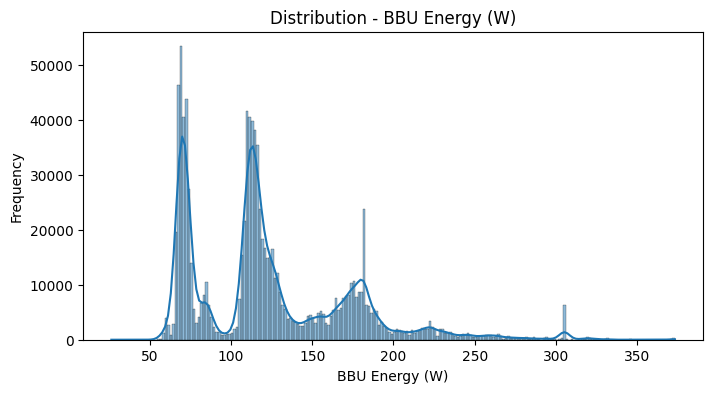

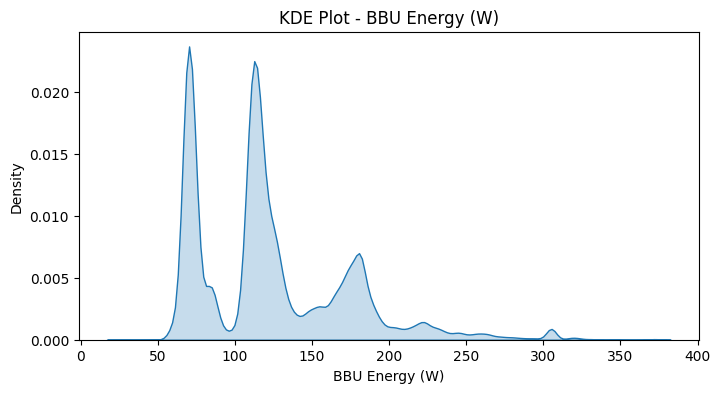

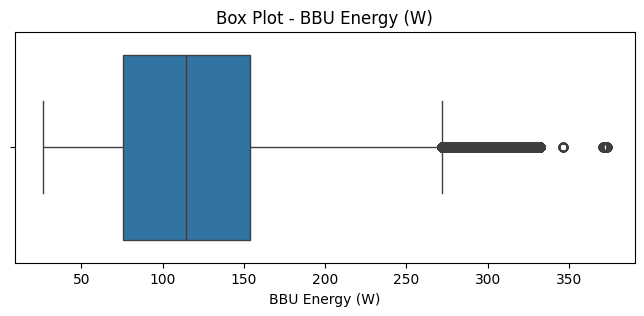

In [30]:
numerical_eda(df,'BBU Energy (W)')

In [31]:
check_outliers(df,'BBU Energy (W)')


Column: BBU Energy (W)
Q1: 75.6
Q3: 154.0
IQR: 78.4
Lower Limit: -42.000000000000014
Upper Limit: 271.6
Number of Outliers: 13727


,Base Station ID,Cell ID,Timestamp,PRB Usage Ratio (%),Traffic Volume (KByte),Number of Users,BBU Energy (W),RRU Energy (W),Channel Shutdown Time (Millisecond),Channel Shutdown Time (Millisecond).1,Deep Sleep Time (Millisecond)
50592,14894,14894-0,00:00,0.51,349744.62,3.75,327.500000,71.002838,0.0,0.0,0.0
50593,14894,14894-0,00:30,0.00,0.00,0.00,322.800000,69.788872,0.0,0.0,0.0
50594,14894,14894-0,01:00,0.00,0.00,0.00,322.800000,67.909955,0.0,0.0,0.0
50595,14894,14894-0,01:30,0.00,0.00,0.00,322.800000,69.290605,0.0,0.0,0.0
50596,14894,14894-0,02:00,0.00,0.00,0.00,322.800000,69.454496,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
1000411,14206,14206-5,21:30,5.24,252873.16,1.44,305.068756,153.533636,0.0,0.0,0.0
1000412,14206,14206-5,22:00,5.16,8305.41,0.82,305.068756,153.377209,0.0,0.0,0.0
1000413,14206,14206-5,22:30,5.18,15866.74,0.71,305.068756,153.417177,0.0,0.0,0.0
1000414,14206,14206-5,23:00,5.13,9998.80,0.51,305.068756,153.324836,0.0,0.0,0.0


In [7]:
df[(df['BBU Energy (W)']>300) & (df['Number of Users']>300) & (df['Traffic Volume (KByte)']>10000)]

,Base Station ID,Cell ID,Timestamp,PRB Usage Ratio (%),Traffic Volume (KByte),Number of Users,BBU Energy (W),RRU Energy (W),Channel Shutdown Time (Millisecond),Channel Shutdown Time (Millisecond).1,Deep Sleep Time (Millisecond)
445029,16082,16082-0,10:30,20.10,25105254.43,334.19,306.0,156.447672,0.0,0.0,0.0
445030,16082,16082-0,11:00,18.26,22706204.23,328.92,306.0,148.285559,0.0,0.0,0.0
445031,16082,16082-0,11:30,25.53,25816942.62,335.06,306.2,175.353329,0.0,0.0,0.0
445032,16082,16082-0,12:00,23.70,28579343.03,349.90,305.9,166.448637,0.0,0.0,0.0
445035,16082,16082-0,13:30,20.79,22798304.43,331.19,305.9,161.500138,0.0,0.0,0.0
445036,16082,16082-0,14:00,19.58,22868722.48,328.16,305.8,155.226730,0.0,0.0,0.0
445037,16082,16082-0,14:30,18.99,22863103.43,300.03,305.8,153.520328,0.0,0.0,0.0
445038,16082,16082-0,15:00,21.10,22900768.28,318.90,305.8,162.312201,0.0,0.0,0.0
445039,16082,16082-0,15:30,20.04,25055799.03,322.81,305.8,156.581964,0.0,0.0,0.0
445041,16082,16082-0,16:30,23.41,31644123.07,323.19,306.1,168.056760,0.0,0.0,0.0


In [8]:
df[(df['Traffic Volume (KByte)']==0)]

,Base Station ID,Cell ID,Timestamp,PRB Usage Ratio (%),Traffic Volume (KByte),Number of Users,BBU Energy (W),RRU Energy (W),Channel Shutdown Time (Millisecond),Channel Shutdown Time (Millisecond).1,Deep Sleep Time (Millisecond)
7,13905,13905-2,03:30,0.00,0.0,0.0,126.000000,55.000000,0.0,0.0,900000.0
8,13905,13905-2,04:00,0.00,0.0,0.0,126.000000,55.000000,0.0,0.0,900000.0
9,13905,13905-2,04:30,0.00,0.0,0.0,126.000000,54.800000,0.0,0.0,900000.0
55,13905,13905-1,03:30,0.00,0.0,0.0,126.000000,72.379919,0.0,0.0,900000.0
56,13905,13905-1,04:00,0.00,0.0,0.0,126.000000,71.452111,0.0,0.0,900000.0
...,...,...,...,...,...,...,...,...,...,...,...
1001049,14239,14239-1,04:30,5.11,0.0,0.0,181.395504,153.286246,0.0,0.0,0.0
1001097,14239,14239-2,04:30,5.49,0.0,0.0,181.395504,153.997406,0.0,0.0,0.0
1001145,14242,14242-0,04:30,12.30,0.0,0.0,181.395504,385.061949,0.0,0.0,0.0
1001193,14242,14242-1,04:30,10.92,0.0,0.0,181.395504,383.460004,0.0,0.0,0.0
